# Second-order circuit discovery on official MIB IOI

This controlled experiment searches only the 12 previously selected GPT-2 Small
attention heads. A circuit **retains** some of them; every other selected head is
patched from its matched official corrupted IOI prompt at all positions. All
unselected model components remain active. Circuit selection uses official
*train* examples and prior train measurements. Validation is held out.

The raw task score is MIB's correct-minus-incorrect IOI logit difference. We
select circuits by **minimizing the absolute change in mean task score** from the
full model. The separately reported custom faithfulness is
`1 - |F(C)-F(full)| / |F(empty)-F(full)|`, where `empty` removes every selected
head. It may be negative or undefined and is **not** MIB CPR/CMD. Matching a
mean score does not imply matching every prompt or the complete transformer.

Run top-to-bottom. Exact oracle enumeration is opt-in and disabled by default.
The prior completed IOI run provides EAP rankings and train singleton/pair
measurements; this notebook independently rechecks model behavior and evaluates
new selected circuits with real model forwards.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from itertools import combinations
from time import perf_counter
import hashlib
import importlib.metadata
import json
import math
import os
import sys
import uuid

ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / 'mib_ioi/runtime.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Open this notebook inside the circuit-sketching repository.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ['HF_HOME'] = str(ROOT / '.cache/huggingface')
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
for variable in ('HF_HOME', 'MPLCONFIGDIR'):
    Path(os.environ[variable]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display, Markdown
from tqdm.auto import tqdm
from mib_ioi import runtime as rt, discovery as disc

SEED = 42
N_COMPONENTS = 12
N_TRAIN = N_VALIDATION = 128
BATCH_SIZE = 8
CIRCUIT_SIZES = (2, 4, 6, 8, 10)
BOOTSTRAP_REPEATS = 300
RUN_ORACLE = False
MAX_ORACLE_CANDIDATES_PER_SIZE = 1000
ORACLE_SIZES = CIRCUIT_SIZES
PRIOR_RUN = ROOT / 'results/mib_ioi_20261014T223008Z_7f3eef49'
MIB_REPO = Path(os.environ.get('MIB_REPO', ROOT / 'external/MIB-circuit-track'))
RUN_DIR = ROOT / 'results' / ('mib_circuit_discovery_' +
          datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
RUN_DIR.mkdir(parents=True, exist_ok=True)
rt.seed_everything(SEED)
if not 2 <= N_COMPONENTS <= 12 or BATCH_SIZE < 1:
    raise ValueError('Use 2-12 prior heads and a positive batch size.')
CIRCUIT_SIZES = tuple(k for k in CIRCUIT_SIZES if 0 <= k <= N_COMPONENTS)
if not CIRCUIT_SIZES:
    raise ValueError('No circuit sizes fit the selected head subset.')
ledger = rt.Ledger('cuda', RUN_DIR)
print('Output:', RUN_DIR)
print('Seed:', SEED, '| Oracle enabled:', RUN_ORACLE, '| Batch size:', BATCH_SIZE)

Seed: 42; TF32 disabled; model.eval() used.
Output: H:\GenAI Research\sketch_prune\results\mib_circuit_discovery_20261015T043327Z_3e398329
Seed: 42 | Oracle enabled: False | Batch size: 8


## 1. Load the prior controlled experiment and official MIB split

The prior files are immutable inputs. EAP was computed on 32 training prompts;
singleton and pair measurements were acquired on 128 train and 128 validation
prompts. Only the **train rows** are used to fit or select circuits. The old
acquisition costs are included later even though those tensors are now cached.
The official MIB loader is used again for fresh exact evaluations.

In [2]:
required = ['experiment_config.json', 'selected_components.csv',
            'official_eap_head_ranking.csv', 'singleton_effects.csv',
            'pairwise_interactions.csv', 'compute_accounting.csv', 'raw_ioi_scores.csv']
missing = [name for name in required if not (PRIOR_RUN / name).is_file()]
if missing:
    raise FileNotFoundError(f'Prior completed IOI run is incomplete: {missing}')
prior_config = json.loads((PRIOR_RUN / 'experiment_config.json').read_text())
prior_components = pd.read_csv(PRIOR_RUN / 'selected_components.csv').sort_values('component_index')
prior_eap = pd.read_csv(PRIOR_RUN / 'official_eap_head_ranking.csv')
prior_singletons = pd.read_csv(PRIOR_RUN / 'singleton_effects.csv')
prior_pairs = pd.read_csv(PRIOR_RUN / 'pairwise_interactions.csv')
prior_costs = pd.read_csv(PRIOR_RUN / 'compute_accounting.csv').set_index('stage')
prior_raw = pd.read_csv(PRIOR_RUN / 'raw_ioi_scores.csv')
if prior_config['seed'] != SEED or prior_config['dataset_splits'] != {
        'train': N_TRAIN, 'validation': N_VALIDATION}:
    raise ValueError('Seed or prompt counts differ from the prior run; regenerate measurements first.')
components = [tuple(map(int, row)) for row in
              prior_components[['layer', 'head']].to_numpy()[:N_COMPONENTS]]
component_names = prior_components.component.iloc[:N_COMPONENTS].tolist()
if len(components) != N_COMPONENTS or len(set(components)) != N_COMPONENTS:
    raise ValueError('Selected component list is incomplete or duplicated.')
if components != [tuple(x) for x in prior_config['components'][:N_COMPONENTS]]:
    raise ValueError('Selected components do not match prior provenance.')
eap_order = [component_names.index(name) for name in prior_eap.component
             if name in component_names]
if len(eap_order) != N_COMPONENTS or len(set(eap_order)) != N_COMPONENTS:
    raise ValueError('Prior EAP ranking does not cover the selected heads.')
with ledger.stage('model_loading'):
    repo, provenance = rt.configure_repository(ROOT, MIB_REPO)
    if (provenance['mib_commit'] != prior_config['provenance']['mib_commit'] or
        provenance['eap_commit'] != prior_config['provenance']['eap_commit']):
        raise RuntimeError('Official MIB revision differs from the prior experiment.')
    model = rt.load_model('cuda')
with ledger.stage('official_data_loading'):
    datasets, manifest, dataset_info = rt.load_splits(
        model, {'train': N_TRAIN, 'validation': N_VALIDATION}, SEED)
for split in ('train', 'validation'):
    old = prior_config['dataset_info'][split]
    new = dataset_info[split]
    if (new['official_fingerprint'] != old['official_fingerprint'] or
        new['selected_filtered_indices'] != old['selected_filtered_indices']):
        raise RuntimeError(f'Official {split} rows differ from the prior experiment.')
manifest.to_csv(RUN_DIR / 'dataset_manifest.csv', index=False)
identity = {'prior_cache_signature': prior_config['cache_signature'],
            'components': components, 'batch_size': BATCH_SIZE,
            'split_fingerprints': {s: dataset_info[s]['selected_fingerprint']
                                   for s in datasets},
            'adapter_sha256': hashlib.sha256((ROOT/'mib_ioi/runtime.py').read_bytes()).hexdigest()}
cache_id = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()
scorer = rt.IOIScorer(model, datasets, components, BATCH_SIZE, ledger,
                      RUN_DIR / 'exact_cache' / cache_id)
display(prior_components.head(N_COMPONENTS))
print('Official MIB commit:', provenance['mib_commit'])
print('Search space:', N_COMPONENTS, 'heads; all others remain active.')

Loaded pretrained model gpt2-small into HookedTransformer
model_loading: 0 actual forward batches, 17.04s wall
Using the latest cached version of the dataset since mib-bench/ioi couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'default' at H:\GenAI Research\sketch_prune\.cache\huggingface\datasets\mib-bench___ioi\default\0.0.0\e5f3468f3af4c0883be35cd3bced8c711c95d286 (last modified on Wed Oct 14 18:13:25 2026).
Using the latest cached version of the dataset since mib-bench/ioi couldn't be found on the Hugging Face Hub (offline mode is enabled).
Found the latest cached dataset configuration 'default' at H:\GenAI Research\sketch_prune\.cache\huggingface\datasets\mib-bench___ioi\default\0.0.0\e5f3468f3af4c0883be35cd3bced8c711c95d286 (last modified on Wed Oct 14 18:13:25 2026).
official_data_loading: 0 actual forward batches, 0.58s wall
    component_index component  ...  rank            selection_source
0                 0 

## 2. Reproduce existing measurements and define circuit evaluation

The same official logit-difference metric and matched
`s2_io_flip_counterfactual` head-result replacement are used. `1` in a mask
means **remove/patch** a selected head. The scorer caches per-prompt scores.
The full and all-removed scores define the faithfulness reference for each
prompt split. One singleton and one pair are recomputed without relying on
the prior score cache to detect convention or data drift.

In [3]:
def exact_score(split, mask, stage):
    mask = np.asarray(mask, dtype=np.int8)
    before_hits = ledger.hits
    with ledger.stage(stage, f'{math.ceil(len(datasets[split])/BATCH_SIZE)} clean batches + '
                      'up to the same donor batches; cached masks use 0 forwards'), ledger.instrument(model):
        scores, accuracies = scorer.score(split, mask)
    row = ledger.stages[-1].copy()
    row['new_cache_hits'] = ledger.hits - before_hits
    return scores, accuracies, row

full_mask = np.zeros(N_COMPONENTS, dtype=np.int8)
empty_mask = np.ones(N_COMPONENTS, dtype=np.int8)
full, empty, references = {}, {}, {}
for split in datasets:
    full[split], _, references[(split, 'full')] = exact_score(
        split, full_mask, f'{split}_full_model')
    empty[split], _, references[(split, 'empty')] = exact_score(
        split, empty_mask, f'{split}_all_selected_heads_removed')
    old_mean = float(prior_raw.query('prompt_split == @split and input == "clean"').mean_logit_diff.iloc[0])
    np.testing.assert_allclose(full[split].mean(), old_mean, atol=3e-4, rtol=1e-5)
    for removed in [(0,), (0, 1)]:
        mask = np.zeros(N_COMPONENTS, dtype=np.int8)
        mask[list(removed)] = 1
        scores, _, _ = exact_score(split, mask, f'{split}_recheck_{len(removed)}')
        if len(removed) == 1:
            prior = prior_singletons.query(
                'prompt_split == @split and component_index == 0').intervened_score.iloc[0]
        else:
            effect = prior_pairs.query('prompt_split == @split and i == 0 and j == 1').true_pair_effect.iloc[0]
            prior = old_mean + effect
        np.testing.assert_allclose(scores.mean(), prior, atol=3e-4, rtol=1e-5)
    print(split, 'full score:', round(float(full[split].mean()), 4),
          '| all selected removed:', round(float(empty[split].mean()), 4))

def evaluate_circuit(mask, split, stage):
    '''Actual official IOI task score; no surrogate enters evaluation.'''
    return exact_score(split, mask, stage)

checks = {'intervention': prior_config['intervention_type'],
          'metric': prior_config['score_semantics'],
          'full_model_mean': {s: float(v.mean()) for s, v in full.items()},
          'all_removed_mean': {s: float(v.mean()) for s, v in empty.items()},
          'reproduction_atol': 3e-4}
rt.write_json(RUN_DIR / 'reproduction_checks.json', checks)

train_full_model: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
train_full_model: 16 actual forward batches, 1.75s wall
train_all_selected_heads_removed: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
train_all_selected_heads_removed: 32 actual forward batches, 2.64s wall
train_recheck_1: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
train_recheck_1: 16 actual forward batches, 1.21s wall
train_recheck_2: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
train_recheck_2: 16 actual forward batches, 1.23s wall
train full score: 3.2767 | all selected removed: -3.6813
validation_full_model: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
validation_full_model: 16 actual forward batches, 1.18s wall
validation_all_selected_heads_removed: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
validation_all_selected_heads_remo

## 3. Fit the train-only first- and second-order intervention models

The design contains each singleton once and each unordered pair once. Fitting
has no intercept because `F(0)-F(0)=0`. Coefficients match the exact train
single/pair effects from the prior run; no validation measurements enter the
fit. Their historical collection costs remain part of discovery cost.

In [4]:
train_single = (prior_singletons.query('prompt_split == "train"')
                .sort_values('component_index').iloc[:N_COMPONENTS])
if train_single.component_index.tolist() != list(range(N_COMPONENTS)):
    raise ValueError('Missing train singleton measurement.')
train_pairs = (prior_pairs.query('prompt_split == "train" and i < @N_COMPONENTS and j < @N_COMPONENTS')
               .sort_values(['i', 'j']))
pair_indices = list(combinations(range(N_COMPONENTS), 2))
if list(zip(train_pairs.i, train_pairs.j)) != pair_indices:
    raise ValueError('Missing, repeated, or out-of-order train pair measurement.')
fit_start = perf_counter()
beta1 = disc.fit_first_order(train_single.effect.to_numpy())
fit_first_seconds = perf_counter() - fit_start
fit_start = perf_counter()
beta2 = disc.fit_second_order(train_single.effect.to_numpy(),
                              train_pairs.true_pair_effect.to_numpy(), pair_indices)
fit_second_seconds = perf_counter() - fit_start
np.savez(RUN_DIR / 'train_coefficients.npz', beta1=beta1, beta2=beta2,
         pairs=np.asarray(pair_indices), components=np.asarray(components))
print('Fitted', len(beta1), 'first-order and', len(beta2)-len(beta1),
      'pair coefficients from train measurements.')
print('First-order fit seconds:', fit_first_seconds,
      '| second-order fit seconds:', fit_second_seconds)

Fitted 12 first-order and 66 pair coefficients from train measurements.
First-order fit seconds: 0.07629020000604214 | second-order fit seconds: 0.01325169999472564


## 4. Select with EAP, first order, and second order

At each size, the two surrogates enumerate all candidate masks **on CPU**
and choose the one with the smallest predicted absolute mean score change.
EAP retains its top-ranked heads. Every selected circuit is then evaluated
with fresh official data and exact model inference on train and validation.
Repeated masks are cached; forward counts below reflect real model calls.

In [5]:
selection_rows, selected_masks, exact_arrays = [], {}, {}
for k in tqdm(CIRCUIT_SIZES, desc='Circuit sizes'):
    count = disc.candidate_count(N_COMPONENTS, k)
    batches_per_mask = 2 * math.ceil(N_TRAIN / BATCH_SIZE)
    print(f'k={k}: {count} CPU surrogate candidates/method; at most '
          f'{6*batches_per_mask} exact forward batches for three methods x two splits.')
    start = perf_counter()
    eap_mask = disc.select_eap(N_COMPONENTS, k, eap_order)
    choices = [('EAP', eap_mask, float('nan'), perf_counter()-start)]
    mask1, pred1, seconds1 = disc.select_surrogate(N_COMPONENTS, k, beta1, 1)
    mask2, pred2, seconds2 = disc.select_surrogate(N_COMPONENTS, k, beta2, 2)
    choices.extend([('first order', mask1, pred1, seconds1),
                    ('second order', mask2, pred2, seconds2)])
    for method, mask, prediction, selection_seconds in choices:
        assert len(disc.retained(mask)) == k and int(mask.sum()) == N_COMPONENTS-k
        selected_masks[(method, k)] = mask
        for split in ('train', 'validation'):
            scores, accuracy, cost = evaluate_circuit(
                mask, split, f'evaluate_{method.replace(" ", "_")}_k{k}_{split}')
            exact_arrays[(method, k, split)] = scores
            full_mean, empty_mean, score_mean = (full[split].mean(),
                                                   empty[split].mean(), scores.mean())
            ci_lo, ci_hi = disc.bootstrap_faithfulness(
                scores, full[split], empty[split], BOOTSTRAP_REPEATS,
                SEED + 100*k + (0 if split == 'train' else 1))
            selection_rows.append({
                'method': method, 'circuit_size': k, 'split': split,
                'retained_heads': json.dumps([component_names[i] for i in disc.retained(mask)]),
                'removed_heads': json.dumps([component_names[i] for i in np.flatnonzero(mask)]),
                'removal_mask': ''.join(map(str, mask)),
                'n_retained': k, 'n_removed': int(mask.sum()),
                'full_task_score': float(full_mean), 'all_removed_task_score': float(empty_mean),
                'actual_task_score': float(score_mean),
                'change_from_full': float(score_mean-full_mean),
                'absolute_score_error': float(abs(score_mean-full_mean)),
                'faithfulness': disc.faithfulness(score_mean, full_mean, empty_mean),
                'faithfulness_ci_low': ci_lo, 'faithfulness_ci_high': ci_hi,
                'top1_accuracy': float(accuracy.mean()),
                'predicted_train_effect': prediction,
                'selection_seconds': selection_seconds if split == 'train' else 0.0,
                'exact_evaluation_seconds': cost['wall_seconds'],
                'forward_batches': cost['forward_passes_batches'],
                'example_forwards': cost['examples_processed'],
                'cache_hits': cost['cache_hits'],
                'peak_cuda_allocated_mib': cost['peak_cuda_allocated_mib']})
selection = pd.DataFrame(selection_rows)
selection.to_csv(RUN_DIR / 'circuit_selection_results.csv', index=False)
display(selection.query('split == "validation"')[[
    'method', 'circuit_size', 'actual_task_score', 'faithfulness',
    'faithfulness_ci_low', 'faithfulness_ci_high', 'forward_batches']])

Circuit sizes:   0%|          | 0/5 [00:00<?, ?it/s]k=2: 66 CPU surrogate candidates/method; at most 192 exact forward batches for three methods x two splits.
evaluate_EAP_k2_train: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
evaluate_EAP_k2_train: 16 actual forward batches, 1.41s wall
evaluate_EAP_k2_validation: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
evaluate_EAP_k2_validation: 16 actual forward batches, 1.45s wall
evaluate_first_order_k2_train: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
evaluate_first_order_k2_train: 16 actual forward batches, 1.45s wall
evaluate_first_order_k2_validation: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
evaluate_first_order_k2_validation: 16 actual forward batches, 1.62s wall
evaluate_second_order_k2_train: 16 clean batches + up to the same donor batches; cached masks use 0 forwards
evaluate_second_order_k2_train: 16 a

## 5. Optional exhaustive oracle over the same 12-head space

The oracle enumerates every `C(12,k)` retained-head set and uses **train**
mean-score preservation to choose the winner. Only that winner is evaluated on
validation. At 128 train prompts and batch size 8, all five default sizes
require 2,046 candidate evaluations and up to roughly 32,736 clean forward
batches, plus donor acquisition. This can take tens of minutes on an RTX 3060.
`RUN_ORACLE` is **False by default**. A per-size candidate cap rejects
partial searches; it never labels a truncated search as exact.

In [6]:
oracle_rows = []
oracle_columns = ['circuit_size', 'candidate_index', 'n_candidates',
                  'removal_mask', 'retained_heads', 'train_task_score',
                  'train_absolute_score_error', 'is_train_winner',
                  'forward_batches', 'example_forwards', 'search_seconds']
oracle_winners = {}
total_candidates = sum(disc.candidate_count(N_COMPONENTS, k)
                       for k in ORACLE_SIZES if k in CIRCUIT_SIZES)
print('Full oracle budget:', total_candidates, 'candidates; approximately',
      total_candidates * math.ceil(N_TRAIN/BATCH_SIZE),
      'clean forward batches plus donor acquisition. Enabled:', RUN_ORACLE)
if RUN_ORACLE:
    for k in ORACLE_SIZES:
        if k not in CIRCUIT_SIZES:
            continue
        count = disc.candidate_count(N_COMPONENTS, k)
        if count > MAX_ORACLE_CANDIDATES_PER_SIZE:
            print(f'Skipping k={k}: {count} exceeds cap {MAX_ORACLE_CANDIDATES_PER_SIZE}')
            continue
        print(f'Oracle k={k}: {count} train candidates; up to '
              f'{count*math.ceil(N_TRAIN/BATCH_SIZE)} new clean batches.', flush=True)
        before = len(ledger.calls)
        start = perf_counter()
        with tqdm(total=count, desc=f'Oracle k={k}') as bar:
            with ledger.stage(f'oracle_search_k{k}', f'{count} exhaustive train circuits'), ledger.instrument(model):
                winner, evaluated = disc.oracle_search(
                    N_COMPONENTS, k, lambda mask: scorer.score('train', mask)[0].mean(),
                    float(full['train'].mean()), MAX_ORACLE_CANDIDATES_PER_SIZE,
                    progress=lambda index, total: bar.update(1))
        elapsed = perf_counter() - start
        stage = ledger.stages[-1]
        oracle_winners[k] = winner
        for index, (mask, score, loss) in enumerate(evaluated, 1):
            oracle_rows.append({'circuit_size': k, 'candidate_index': index,
                'n_candidates': count, 'removal_mask': ''.join(map(str, mask)),
                'retained_heads': json.dumps([component_names[i] for i in disc.retained(mask)]),
                'train_task_score': score, 'train_absolute_score_error': loss,
                'is_train_winner': bool(np.array_equal(mask, winner)),
                'forward_batches': stage['forward_passes_batches'] if index == 1 else 0,
                'example_forwards': stage['examples_processed'] if index == 1 else 0,
                'search_seconds': elapsed if index == 1 else 0.0})
        if len(evaluated) != count:
            raise AssertionError('Oracle did not evaluate all train candidates.')
        for split in ('train', 'validation'):
            scores, accuracy, cost = evaluate_circuit(
                winner, split, f'oracle_winner_k{k}_{split}')
            exact_arrays[('oracle', k, split)] = scores
            full_mean, empty_mean, score_mean = (full[split].mean(),
                                                   empty[split].mean(), scores.mean())
            ci_lo, ci_hi = disc.bootstrap_faithfulness(
                scores, full[split], empty[split], BOOTSTRAP_REPEATS, SEED+300+k)
            selection_rows.append({
                'method': 'oracle', 'circuit_size': k, 'split': split,
                'retained_heads': json.dumps([component_names[i] for i in disc.retained(winner)]),
                'removed_heads': json.dumps([component_names[i] for i in np.flatnonzero(winner)]),
                'removal_mask': ''.join(map(str, winner)),
                'n_retained': k, 'n_removed': int(winner.sum()),
                'full_task_score': float(full_mean), 'all_removed_task_score': float(empty_mean),
                'actual_task_score': float(score_mean), 'change_from_full': float(score_mean-full_mean),
                'absolute_score_error': float(abs(score_mean-full_mean)),
                'faithfulness': disc.faithfulness(score_mean, full_mean, empty_mean),
                'faithfulness_ci_low': ci_lo, 'faithfulness_ci_high': ci_hi,
                'top1_accuracy': float(accuracy.mean()), 'predicted_train_effect': float('nan'),
                'selection_seconds': elapsed if split == 'train' else 0.0,
                'exact_evaluation_seconds': cost['wall_seconds'],
                'forward_batches': cost['forward_passes_batches'],
                'example_forwards': cost['examples_processed'],
                'cache_hits': cost['cache_hits'],
                'peak_cuda_allocated_mib': cost['peak_cuda_allocated_mib']})
    selection = pd.DataFrame(selection_rows)
    selection.to_csv(RUN_DIR / 'circuit_selection_results.csv', index=False)
pd.DataFrame(oracle_rows, columns=oracle_columns).to_csv(
    RUN_DIR / 'oracle_search_results.csv', index=False)
print('Oracle sizes completed:', sorted(oracle_winners))

Full oracle budget: 2046 candidates; approximately 32736 clean forward batches plus donor acquisition. Enabled: False
Oracle sizes completed: []


## 6. Head differences, oracle gaps, and held-out generalization

Pair terms below show which removed-head interactions distinguish the two
selected masks. A method can beat the *train-selected* oracle on validation:
that is a generalization difference, not an oracle implementation error.

In [7]:
diff_rows = []
for k in CIRCUIT_SIZES:
    z1, z2 = selected_masks[('first order', k)], selected_masks[('second order', k)]
    t1, t2 = disc.interaction_terms(z1, beta2), disc.interaction_terms(z2, beta2)
    changing_terms = sorted(
        [{'pair': [component_names[i], component_names[j]],
          'contribution_difference': t2.get((i, j), 0.0)-t1.get((i, j), 0.0)}
         for i, j in pair_indices if abs(t2.get((i, j), 0.0)-t1.get((i, j), 0.0)) > 1e-12],
        key=lambda item: -abs(item['contribution_difference']))
    first_val = selection.query('method == "first order" and circuit_size == @k and split == "validation"').iloc[0]
    second_val = selection.query('method == "second order" and circuit_size == @k and split == "validation"').iloc[0]
    diff_rows.append({
        'circuit_size': k, 'first_retained': first_val.retained_heads,
        'second_retained': second_val.retained_heads,
        'first_only_heads': json.dumps([component_names[i] for i in set(disc.retained(z1))-set(disc.retained(z2))]),
        'second_only_heads': json.dumps([component_names[i] for i in set(disc.retained(z2))-set(disc.retained(z1))]),
        'first_selection_predicted_first_order': disc.predicted_effect(z1, beta1, 1),
        'first_selection_predicted_second_order': disc.predicted_effect(z1, beta2, 2),
        'second_selection_predicted_first_order': disc.predicted_effect(z2, beta1, 1),
        'second_selection_predicted_second_order': disc.predicted_effect(z2, beta2, 2),
        'first_true_validation_effect': first_val.change_from_full,
        'second_true_validation_effect': second_val.change_from_full,
        'second_minus_first_validation_faithfulness': second_val.faithfulness-first_val.faithfulness,
        'second_better_on_validation': bool(second_val.absolute_score_error < first_val.absolute_score_error),
        'changed_pair_terms': json.dumps(changing_terms)})
differences = pd.DataFrame(diff_rows)
differences.to_csv(RUN_DIR / 'first_vs_second_order.csv', index=False)
display(differences[['circuit_size', 'first_only_heads', 'second_only_heads',
                     'second_minus_first_validation_faithfulness',
                     'second_better_on_validation']])

comparison_rows = []
for row in selection.query('split == "validation"').itertuples():
    oracle = selection.query('method == "oracle" and split == "validation" and circuit_size == @row.circuit_size')
    oracle_gap = float('nan')
    faith_gap = float('nan')
    overlap = float('nan')
    recovered = float('nan')
    if len(oracle):
        ref = oracle.iloc[0]
        oracle_gap = row.absolute_score_error-ref.absolute_score_error
        faith_gap = ref.faithfulness-row.faithfulness
        overlap = len(set(json.loads(row.retained_heads)) & set(json.loads(ref.retained_heads)))
        empty_loss = abs(row.all_removed_task_score-row.full_task_score)
        denom = empty_loss-ref.absolute_score_error
        if denom > 1e-12:
            recovered = (empty_loss-row.absolute_score_error)/denom
    comparison_rows.append({'method': row.method, 'circuit_size': row.circuit_size,
        'task_score': row.actual_task_score, 'faithfulness': row.faithfulness,
        'oracle_gap_absolute_score_error': oracle_gap,
        'oracle_faithfulness_gap': faith_gap, 'head_overlap_with_oracle': overlap,
        'fraction_oracle_attainable_improvement': recovered,
        'runtime_seconds': row.selection_seconds+row.exact_evaluation_seconds})
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(RUN_DIR / 'oracle_comparison.csv', index=False)
display(comparison)

   circuit_size  ... second_better_on_validation
0             2  ...                        True
1             4  ...                       False
2             6  ...                        True
3             8  ...                        True
4            10  ...                       False

[5 rows x 5 columns]
          method  ...  runtime_seconds
0            EAP  ...         1.446338
1    first order  ...         1.624118
2   second order  ...         1.483724
3            EAP  ...         1.407413
4    first order  ...         1.494253
5   second order  ...         1.537462
6            EAP  ...         1.412276
7    first order  ...         1.383941
8   second order  ...         1.387806
9            EAP  ...         1.316311
10   first order  ...         1.300636
11  second order  ...         1.333536
12           EAP  ...         1.291580
13   first order  ...         0.000155
14  second order  ...         1.274326

[15 rows x 9 columns]


## 7. Full discovery cost and figures

Historical EAP, singleton, and pair acquisition costs are charged to the
methods that need them. The singleton/pair stages in the previous run acquired
**both train and validation** effects, so these recorded costs are conservative
for a train-only deployment. New fit, search, and exact-evaluation costs are
separate. Each size is shown as a standalone discovery run, so reused
acquisition is repeated across size rows; do not sum those rows. Model loading
and official data loading are shared setup. Cache hits contribute no forward
batches. Figures use held-out validation scores only.

notebook_cell_15:75: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
notebook_cell_15:75: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
notebook_cell_15:75: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
notebook_cell_15:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
          method  circuit_size  ...  total_forward_batches  historical_pair_seconds
0            EAP             2  ...                    120                 0.000000
1            EAP             4  ...                    120                 0.000000
2            EAP             6  ...                    120                 0.000000
3            EAP             8  ...                    120                 0.000000
4            EAP            10  ...                    120                 0.000000
5    first order             2  ...                    544                 0.000000
6    first order             4  

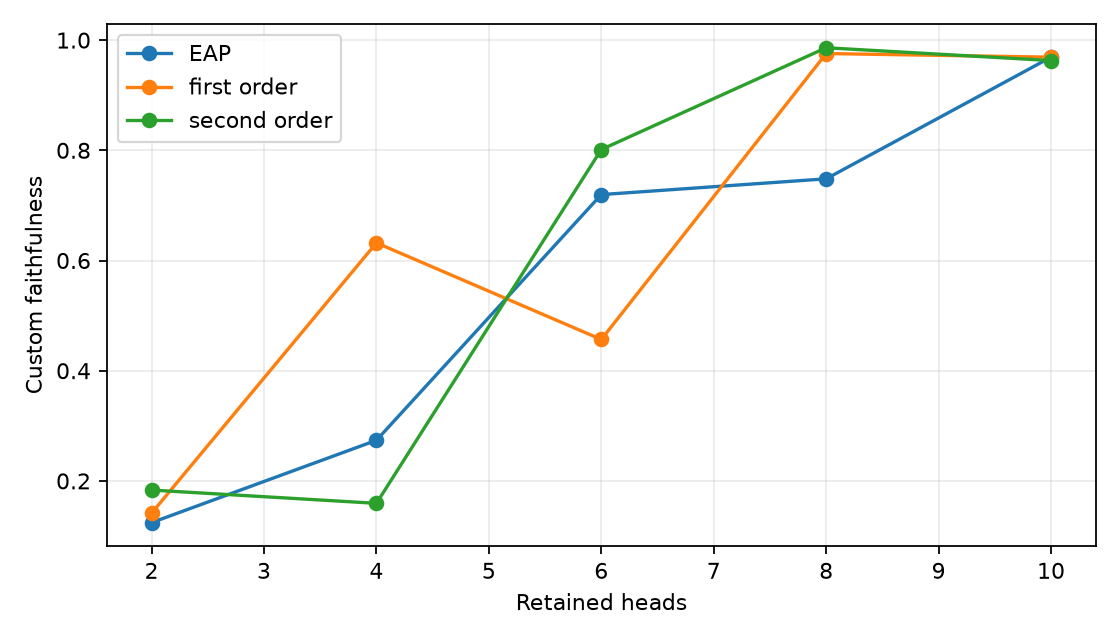

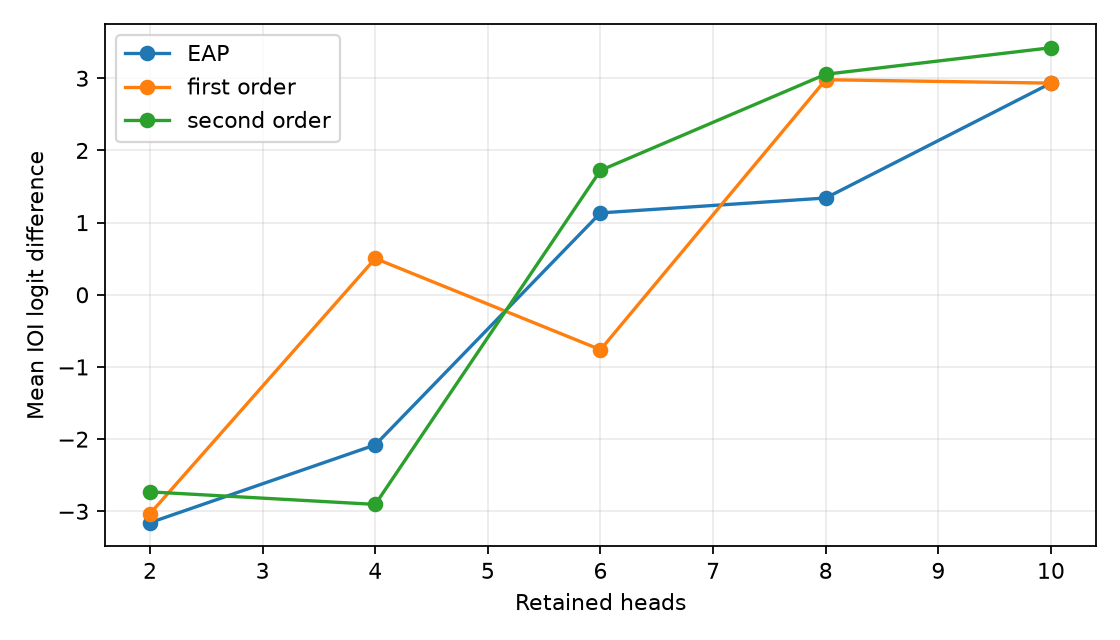

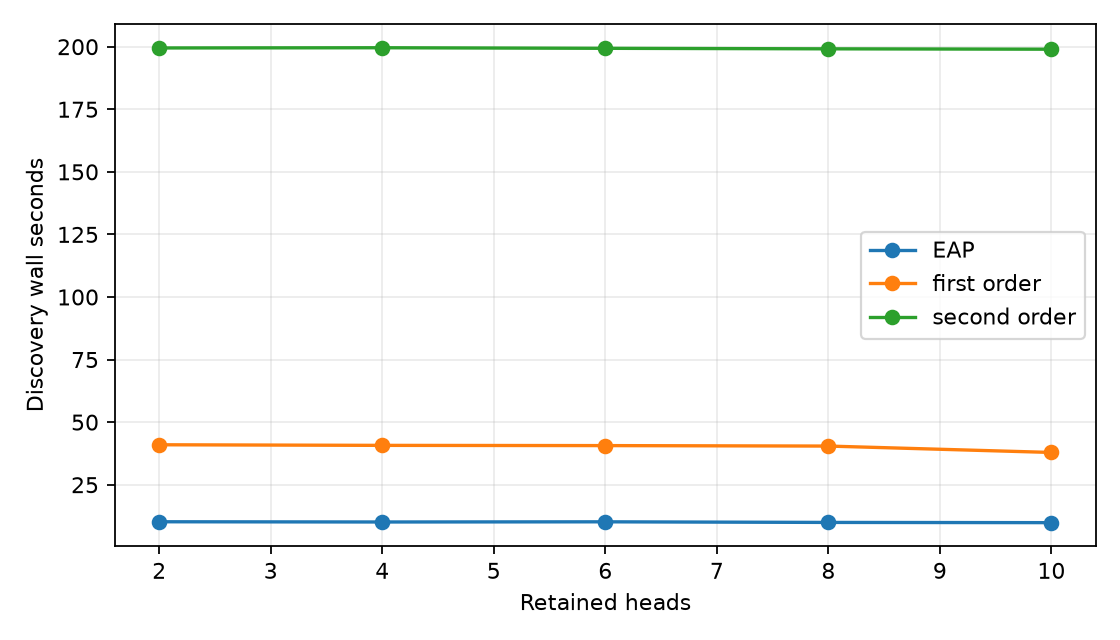

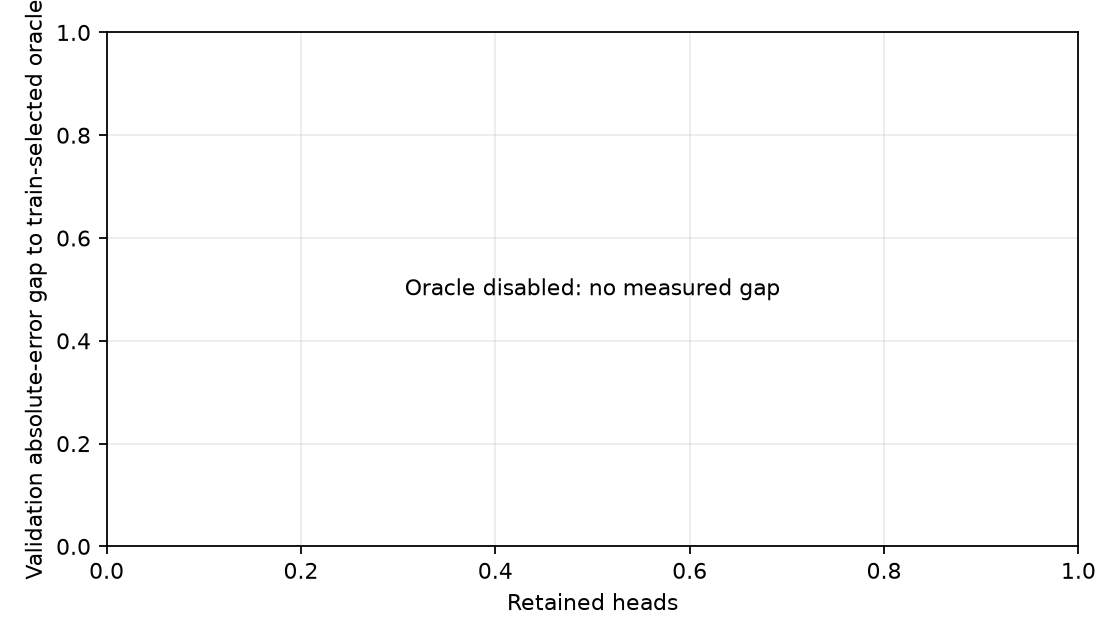

In [8]:
historical = {}
for stage in ['raw_ioi_scores', 'official_eap_selection', 'singletons', 'exact_pairs']:
    row = prior_costs.loc[stage]
    historical[stage] = {'seconds': float(row.wall_seconds),
                         'forward_batches': int(row.forward_passes_batches),
                         'example_forwards': int(row.examples_processed),
                         'peak_cuda_allocated_mib': float(row.peak_cuda_allocated_mib)}
cost_rows = []
for method in selection.method.unique():
    for k in CIRCUIT_SIZES:
        matching = selection.query('method == @method and circuit_size == @k')
        if matching.empty:
            continue
        prior_stages = (['raw_ioi_scores', 'official_eap_selection'] if method == 'EAP' else
                        ['raw_ioi_scores', 'singletons'] if method == 'first order' else
                        ['raw_ioi_scores', 'singletons', 'exact_pairs'] if method == 'second order'
                        else ['raw_ioi_scores'])
        h = {stage: historical[stage] if stage in prior_stages
             else {'seconds': 0.0, 'forward_batches': 0,
                   'example_forwards': 0, 'peak_cuda_allocated_mib': 0.0}
             for stage in historical}
        fit_seconds = (fit_first_seconds if method == 'first order' else
                       fit_first_seconds+fit_second_seconds if method == 'second order' else 0.0)
        search_seconds = float(matching.selection_seconds.sum())
        eval_seconds = float(matching.exact_evaluation_seconds.sum())
        eval_batches = int(matching.forward_batches.sum())
        eval_examples = int(matching.example_forwards.sum())
        oracle_stage = next((s for s in ledger.stages if s['stage'] == f'oracle_search_k{k}'), None)
        oracle_seconds = float(oracle_stage['wall_seconds']) if method == 'oracle' and oracle_stage else 0.0
        oracle_batches = int(oracle_stage['forward_passes_batches']) if method == 'oracle' and oracle_stage else 0
        oracle_examples = int(oracle_stage['examples_processed']) if method == 'oracle' and oracle_stage else 0
        acquired_seconds = sum(v['seconds'] for v in h.values())
        acquired_batches = sum(v['forward_batches'] for v in h.values())
        acquired_examples = sum(v['example_forwards'] for v in h.values())
        cost_rows.append({
            'method': method, 'circuit_size': k,
            'historical_EAP_seconds': h['official_eap_selection']['seconds'],
            'historical_singleton_seconds': h['singletons']['seconds'],
            'historical_pair_seconds': h['exact_pairs']['seconds'],
            'historical_raw_baseline_seconds': h['raw_ioi_scores']['seconds'],
            'fit_seconds': fit_seconds, 'surrogate_or_EAP_selection_seconds':
            search_seconds if method != 'oracle' else 0.0,
            'final_exact_evaluation_seconds': eval_seconds,
            'oracle_exhaustive_search_seconds': oracle_seconds,
            'total_discovery_seconds': acquired_seconds+fit_seconds+search_seconds+eval_seconds,
            'historical_acquisition_forward_batches': acquired_batches,
            'historical_acquisition_example_forwards': acquired_examples,
            'final_exact_forward_batches': eval_batches,
            'final_exact_example_forwards': eval_examples,
            'oracle_search_forward_batches': oracle_batches,
            'oracle_search_example_forwards': oracle_examples,
            'total_forward_batches': acquired_batches+eval_batches+oracle_batches,
            'total_example_forwards': acquired_examples+eval_examples+oracle_examples,
            'peak_cuda_allocated_mib': max(
                float(matching.peak_cuda_allocated_mib.max()),
                *(v['peak_cuda_allocated_mib'] for v in h.values()))})
costs = pd.DataFrame(cost_rows)
costs.to_csv(RUN_DIR / 'runtime_comparison.csv', index=False)
ledger.save()

validation = selection.query('split == "validation"')
for filename, field, ylabel in [
        ('circuit_faithfulness.png', 'faithfulness', 'Custom faithfulness'),
        ('circuit_scores.png', 'actual_task_score', 'Mean IOI logit difference'),
        ('compute_comparison.png', 'total_discovery_seconds', 'Discovery wall seconds')]:
    fig, ax = plt.subplots(figsize=(7, 4))
    source = costs if field == 'total_discovery_seconds' else validation
    for method, group in source.groupby('method'):
        ax.plot(group.circuit_size, group[field], marker='o', label=method)
    ax.set(xlabel='Retained heads', ylabel=ylabel)
    ax.grid(alpha=.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(RUN_DIR / filename, dpi=160)
    plt.show()
fig, ax = plt.subplots(figsize=(7, 4))
if comparison.oracle_gap_absolute_score_error.notna().any():
    for method, group in comparison.groupby('method'):
        ax.plot(group.circuit_size, group.oracle_gap_absolute_score_error,
                marker='o', label=method)
    ax.legend()
else:
    ax.text(.5, .5, 'Oracle disabled: no measured gap', ha='center', va='center',
            transform=ax.transAxes)
ax.set(xlabel='Retained heads', ylabel='Validation absolute-error gap to train-selected oracle')
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(RUN_DIR / 'oracle_gap.png', dpi=160)
plt.show()
display(costs[['method', 'circuit_size', 'total_discovery_seconds',
               'total_forward_batches', 'historical_pair_seconds']])

## 8. Results-only checkpoint and provenance

This cell writes conclusions only from the measured rows. Without oracle
execution, oracle claims remain explicitly unavailable. This experiment is
head-level and cannot be compared directly to a full MIB edge-circuit
leaderboard submission.

In [9]:
summary = []
val = selection.query('split == "validation"')
for opponent in ('EAP', 'first order'):
    diffs = []
    for k in CIRCUIT_SIZES:
        second = val.query('method == "second order" and circuit_size == @k')
        other = val.query('method == @opponent and circuit_size == @k')
        if len(second) and len(other):
            diffs.append(float(second.absolute_score_error.iloc[0] -
                               other.absolute_score_error.iloc[0]))
    summary.append(f'Second order versus {opponent}: lower validation absolute '
                   f'score error at {sum(d<0 for d in diffs)}/{len(diffs)} tested '
                   f'circuit sizes; mean error difference {np.mean(diffs):+.4f}.')
if oracle_winners:
    gaps = comparison.query('method == "second order"').oracle_gap_absolute_score_error.dropna()
    summary.append(f'Second-order validation gap to train-selected oracle: '
                   f'mean {gaps.mean():+.4f} across {len(gaps)} sizes.')
else:
    summary.append('Exact oracle was disabled; proximity to optimal restricted '
                   'train circuits was not measured.')
summary.append('Per-size outcomes, prompt-bootstrap intervals, and acquisition '
               'costs are in the CSV files; this is not MIB CPR/CMD.')
(RUN_DIR/'research_checkpoint.md').write_text('\n\n'.join(summary)+'\n', encoding='utf-8')
config = {'model': 'gpt2-small', 'task': 'ioi', 'official_dataset': 'mib-bench/ioi',
          'train_examples': N_TRAIN, 'validation_examples': N_VALIDATION,
          'dataset_info': dataset_info, 'seed': SEED, 'batch_size': BATCH_SIZE,
          'component_list': components, 'circuit_sizes': CIRCUIT_SIZES,
          'intervention': prior_config['intervention_type'],
          'selection_objective': 'minimize absolute mean IOI logit-difference change from full',
          'faithfulness': '1 - abs(score-full)/abs(all_selected_removed-full); custom, not MIB CPR/CMD',
          'prior_run': str(PRIOR_RUN), 'prior_run_cache_signature': prior_config['cache_signature'],
          'official_provenance': provenance, 'run_oracle': RUN_ORACLE,
          'oracle_sizes': ORACLE_SIZES, 'max_oracle_candidates_per_size': MAX_ORACLE_CANDIDATES_PER_SIZE,
          'oracle_completed_sizes': sorted(oracle_winners), 'bootstrap_repeats': BOOTSTRAP_REPEATS,
          'package_versions': {p: importlib.metadata.version(p) for p in [
              'torch', 'transformer-lens', 'numpy', 'pandas', 'matplotlib', 'datasets']},
          'cost_scope': 'Standalone cost per circuit size; prior singleton/pair stages included train and validation; repeated acquisition must not be summed across size rows.',
          'notebook_source_sha256': hashlib.sha256(
              (ROOT/'notebooks/mib_circuit_discovery.ipynb').read_bytes()).hexdigest()}
rt.write_json(RUN_DIR/'experiment_config.json', config)
ledger.save()
display(Markdown('\n\n'.join(summary)))
print('Output:', RUN_DIR)
print('Current-run real forward batches:', len(ledger.calls))
print('Current-run example-forwards:', sum(c['batch_size'] for c in ledger.calls))

<IPython.core.display.Markdown object>
Output: H:\GenAI Research\sketch_prune\results\mib_circuit_discovery_20261015T043327Z_3e398329
Current-run real forward batches: 608
Current-run example-forwards: 4864


Second order versus EAP: lower validation absolute score error at 3/5 tested circuit sizes; mean error difference -0.3722.

Second order versus first order: lower validation absolute score error at 3/5 tested circuit sizes; mean error difference +0.1179.

Exact oracle was disabled; proximity to optimal restricted train circuits was not measured.

Per-size outcomes, prompt-bootstrap intervals, and acquisition costs are in the CSV files; this is not MIB CPR/CMD.
